# Herenco Room Classification
**BlueprintCNN (Baseline) vs EfficientNetB0 (Transfer Learning)**

| Setting | Value |
|---|---|
| Dataset | Herenco building images |
| Task | 15-class room type classification |
| Split | Project-level 70 / 15 / 15 |
| Epochs | 20 (Phase 1) + 20 (Phase 2 fine-tune) |
| Hardware | GPU (Colab) |

## 1  —  Dependencies & Configuration

In [1]:
# ── Install extra packages (Colab) ────────────────────────────────────────────
!pip install -q albumentations opencv-python

# ── Standard library ─────────────────────────────────────────────────────────
import os
import gc
import random
import warnings
from pathlib import Path
from collections import Counter

# ── Third-party ───────────────────────────────────────────────────────────────
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models

import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'PyTorch  : {torch.__version__}')
print(f'Device   : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU      : {torch.cuda.get_device_name(0)}')

PyTorch  : 2.11.0+cu128
Device   : cuda
GPU      : Tesla T4


In [2]:
# ── Hyperparameters & global constants ────────────────────────────────────────
# Edit only this cell to change training behaviour.

IMG_SIZE    = 224          # input resolution for both models
BATCH_SIZE  = 8            # reduce to 4 if GPU OOM
EPOCHS      = 20           # epochs per phase
SUBSET      = 1.0          # 1.0 = full data; 0.5 = 50% for quick tests

# ImageNet statistics (used for EfficientNetB0 normalisation)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Blueprint statistics (estimated from Herenco data)
BLUEPRINT_MEAN = [0.93, 0.93, 0.93]
BLUEPRINT_STD  = [0.17, 0.17, 0.17]

print('Configuration')
print(f'  IMG_SIZE   : {IMG_SIZE}')
print(f'  BATCH_SIZE : {BATCH_SIZE}')
print(f'  EPOCHS     : {EPOCHS}  (x2 phases for EfficientNetB0 = {EPOCHS*2} total)')
print(f'  SUBSET     : {int(SUBSET*100)}% of data')

Configuration
  IMG_SIZE   : 224
  BATCH_SIZE : 8
  EPOCHS     : 20  (x2 phases for EfficientNetB0 = 40 total)
  SUBSET     : 100% of data


## 2  —  Upload & Locate Dataset

In [3]:
from google.colab import files
import zipfile

uploaded = files.upload()
zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/')

# Support multiple possible extraction paths
CANDIDATE_ROOTS = [
    '/content/herenco_room/classification',
    '/content/classification',
    '/content/herenco_room',
]
DATA_ROOT = next(
    (Path(p) for p in CANDIDATE_ROOTS if Path(p).exists()), None
)
assert DATA_ROOT is not None, 'Dataset root not found — check zip structure.'

n_images = len(list(DATA_ROOT.rglob('*.png')))
print(f'DATA_ROOT : {DATA_ROOT}')
print(f'PNG files : {n_images:,}')

Saving herenco_room.zip to herenco_room.zip
DATA_ROOT : /content/herenco_room/classification
PNG files : 1,517


## 3  —  Data Loading & Exploration

In [4]:
# ── Build flat path/label lists ───────────────────────────────────────────────
all_paths: list  = []
all_labels: list = []

for building_dir in sorted(DATA_ROOT.iterdir()):
    if not building_dir.is_dir():
        continue
    for room_dir in sorted(building_dir.iterdir()):
        if not room_dir.is_dir():
            continue
        for img_path in room_dir.glob('*.png'):
            all_paths.append(img_path)
            all_labels.append(room_dir.name)

ALL_CLASSES  = sorted(set(all_labels))
NUM_CLASSES  = len(ALL_CLASSES)
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(ALL_CLASSES)}
IDX_TO_CLASS = {idx: cls for cls, idx in CLASS_TO_IDX.items()}

print(f'Total images : {len(all_paths):,}')
print(f'Classes      : {NUM_CLASSES}')
print('\nClass list:')
for i, cls in enumerate(ALL_CLASSES):
    print(f'  [{i:2d}] {cls}')

Total images : 1,517
Classes      : 19

Class list:
  [ 0] bathroom_toilet
  [ 1] bedroom_relax
  [ 2] changing_room
  [ 3] class_room
  [ 4] common_room_living_room
  [ 5] dining_room_cafeteria
  [ 6] hallway_corridor
  [ 7] kitchen
  [ 8] laundry_room
  [ 9] library
  [10] lobby_entrance
  [11] maintenance_utility_technical
  [12] medical_room
  [13] meeting_room
  [14] office_workspace
  [15] shower
  [16] stairwell_elevator
  [17] storage_closet
  [18] waiting_room


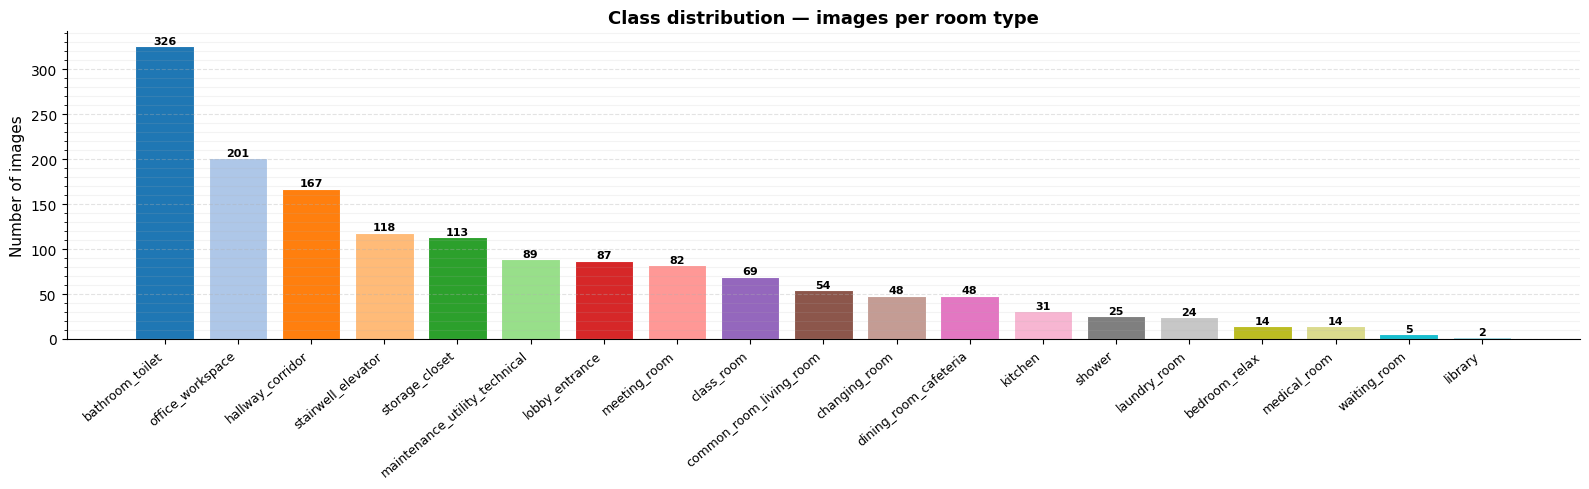

Saved: class_distribution.png


In [5]:
# ── Class distribution bar chart ──────────────────────────────────────────────
label_counts  = Counter(all_labels)
sorted_items  = sorted(label_counts.items(), key=lambda x: -x[1])
cls_names, cls_counts = zip(*sorted_items)

palette = plt.cm.tab20(np.linspace(0, 1, len(cls_names)))

fig, ax = plt.subplots(figsize=(16, 5))
bars = ax.bar(cls_names, cls_counts, color=palette, edgecolor='white', linewidth=0.8)

for bar, cnt in zip(bars, cls_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        str(cnt), ha='center', va='bottom', fontsize=8, fontweight='bold',
    )

ax.set_xticks(range(len(cls_names)))
ax.set_xticklabels(cls_names, rotation=40, ha='right', fontsize=9)
ax.set_ylabel('Number of images', fontsize=11)
ax.set_title('Class distribution — images per room type', fontsize=13, fontweight='bold')
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.grid(axis='y', which='major', alpha=0.35, linestyle='--')
ax.grid(axis='y', which='minor', alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: class_distribution.png')

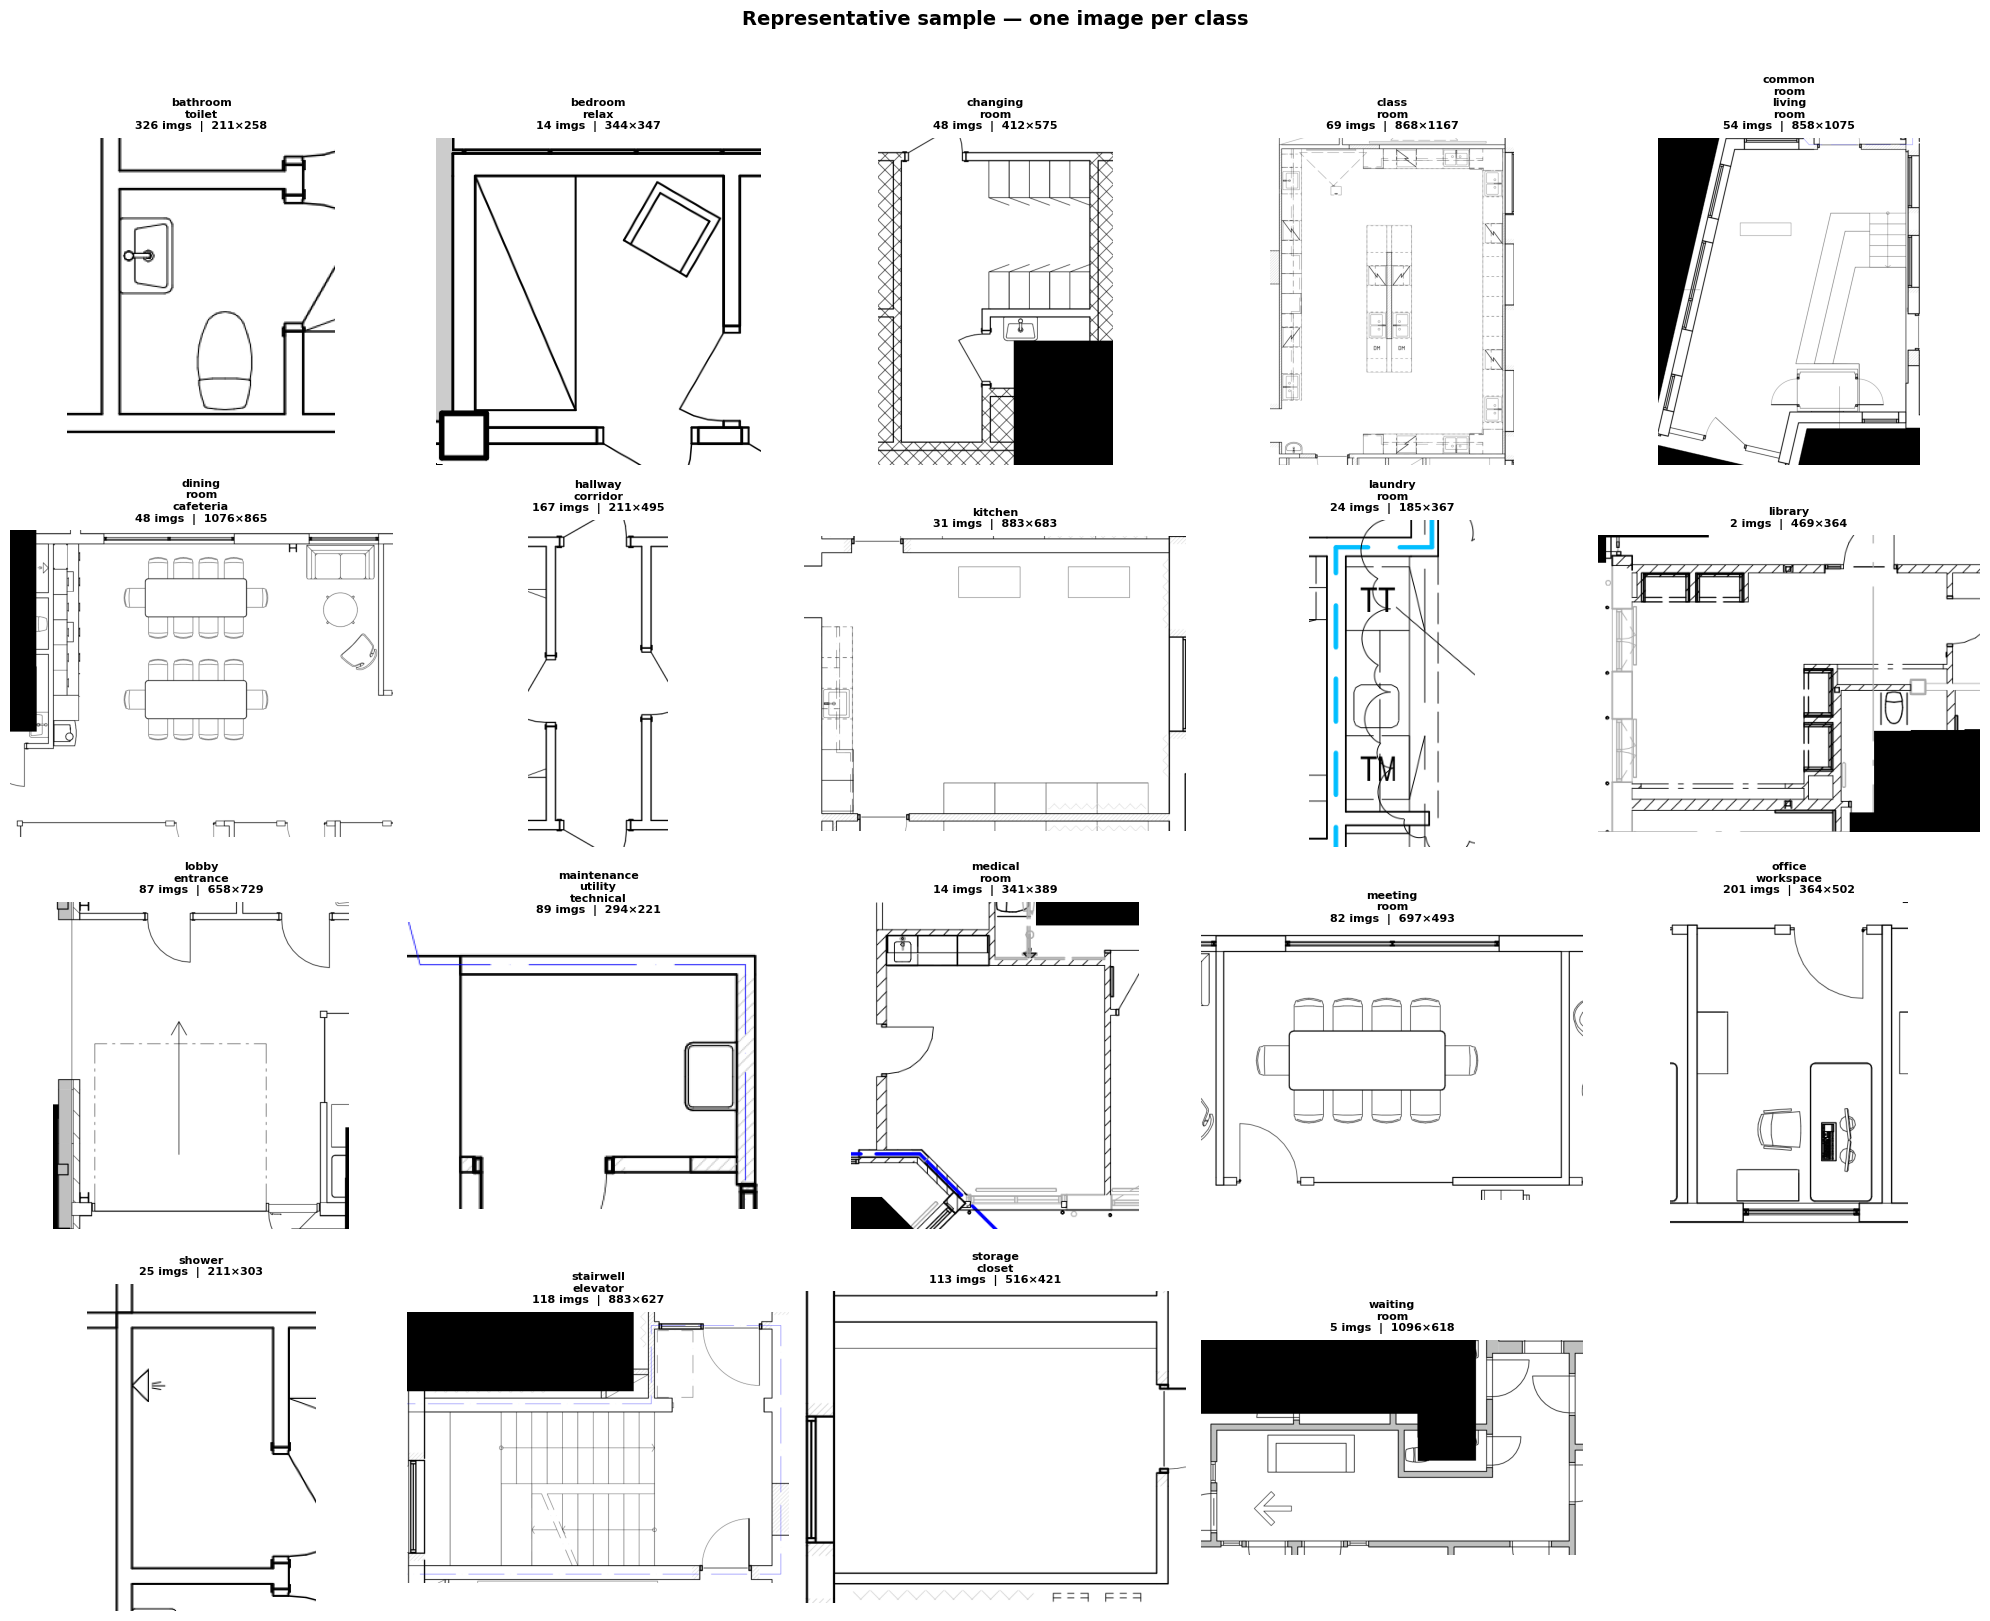

Saved: sample_per_class.png


In [6]:
# ── Sample grid — one image per class ─────────────────────────────────────────
ncols = 5
nrows = (NUM_CLASSES + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4))
fig.suptitle('Representative sample — one image per class', fontsize=14,
             fontweight='bold', y=1.01)

for ax, cls in zip(axes.flatten(), ALL_CLASSES):
    sample = next(p for p, l in zip(all_paths, all_labels) if l == cls)
    img    = Image.open(sample).convert('RGB')
    w, h   = img.size
    ax.imshow(img)
    ax.set_title(
        f'{cls.replace("_", chr(10))}\n{label_counts[cls]} imgs  |  {w}×{h}',
        fontsize=8, fontweight='bold',
    )
    ax.axis('off')

for ax in axes.flatten()[NUM_CLASSES:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('sample_per_class.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: sample_per_class.png')

## 4  —  Preprocessing & Augmentation

In [7]:
def preprocess(img: Image.Image) -> np.ndarray:
    """
    Convert a PIL image to a CLAHE-enhanced numpy array of shape (H, W, 3).

    Steps:
        1. Ensure RGB.
        2. Pad shorter side with white to make the image square (preserves
           aspect ratio without distortion).
        3. Resize to IMG_SIZE × IMG_SIZE with Lanczos resampling.
        4. Apply CLAHE on the luminance channel to normalise lighting
           variations common in construction-site photography.
    """
    img = img.convert('RGB')

    # Step 2 — pad to square
    w, h   = img.size
    side   = max(w, h)
    canvas = Image.new('RGB', (side, side), (255, 255, 255))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))

    # Step 3 — resize
    canvas = canvas.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)

    # Step 4 — CLAHE on luminance
    gray     = np.array(canvas.convert('L'))
    clahe    = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    rgb      = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)
    return rgb


print('preprocess() ready')

preprocess() ready


In [8]:
# ── Albumentations pipelines ──────────────────────────────────────────────────
# Two separate pipelines so val/test are never augmented.

train_transforms = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(
        shift_limit=0.05, scale_limit=0.15, rotate_limit=10,
        border_mode=cv2.BORDER_CONSTANT, value=255, p=0.5,
    ),
    A.OneOf([
        A.Sharpen(alpha=(0.1, 0.3), lightness=(0.9, 1.1), p=1.0),
        A.UnsharpMask(blur_limit=(1, 3), alpha=(0.1, 0.3), p=1.0),
    ], p=0.4),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.2, p=0.4),
    A.GridDropout(
        ratio=0.08, unit_size_min=8, unit_size_max=20, fill_value=255, p=0.2,
    ),
    A.Normalize(mean=BLUEPRINT_MEAN, std=BLUEPRINT_STD),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Normalize(mean=BLUEPRINT_MEAN, std=BLUEPRINT_STD),
    ToTensorV2(),
])

# Separate ImageNet-normalised pipelines for EfficientNetB0
train_transforms_eff = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(
        shift_limit=0.05, scale_limit=0.15, rotate_limit=10,
        border_mode=cv2.BORDER_CONSTANT, value=255, p=0.5,
    ),
    A.OneOf([
        A.Sharpen(alpha=(0.1, 0.3), lightness=(0.9, 1.1), p=1.0),
        A.UnsharpMask(blur_limit=(1, 3), alpha=(0.1, 0.3), p=1.0),
    ], p=0.4),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.2, p=0.4),
    A.GridDropout(
        ratio=0.08, unit_size_min=8, unit_size_max=20, fill_value=255, p=0.2,
    ),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

val_transforms_eff = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

print('Augmentation pipelines ready')

Augmentation pipelines ready


## 5  —  Dataset Splits & DataLoaders

In [9]:
class RoomDataset(Dataset):
    """PyTorch Dataset for Herenco room images.

    Parameters
    ----------
    paths : list[Path]
        Absolute paths to PNG images.
    labels : list[str]
        Room-type string labels corresponding to each path.
    transform : albumentations.Compose, optional
        Augmentation/normalisation pipeline applied after preprocessing.
    """

    def __init__(self, paths: list, labels: list, transform=None):
        self.paths     = paths
        self.labels    = [CLASS_TO_IDX[l] for l in labels]
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        img = Image.open(self.paths[idx])
        arr = preprocess(img)                           # → (H, W, 3) uint8
        if self.transform:
            arr = self.transform(image=arr)['image']   # → torch.Tensor
        return arr, self.labels[idx]


# ── Project-level split (prevents data leakage across buildings) ──────────────
building_ids       = sorted([d.name for d in DATA_ROOT.iterdir() if d.is_dir()])
train_bids, temp   = train_test_split(building_ids, test_size=0.30, random_state=SEED)
val_bids,  test_bids = train_test_split(temp,        test_size=0.50, random_state=SEED)


def collect_split(bid_list: list) -> tuple:
    """Return (paths, labels) for a list of building IDs."""
    paths, labels = [], []
    for bid in bid_list:
        for room_dir in (DATA_ROOT / bid).iterdir():
            if not room_dir.is_dir():
                continue
            for img_path in room_dir.glob('*.png'):
                paths.append(img_path)
                labels.append(room_dir.name)
    return paths, labels


train_paths, train_labels = collect_split(train_bids)
val_paths,   val_labels   = collect_split(val_bids)
test_paths,  test_labels  = collect_split(test_bids)


def subsample(paths, labels, fraction: float) -> tuple:
    """Randomly keep `fraction` of the data (minimum one example per class)."""
    n   = max(NUM_CLASSES, int(len(paths) * fraction))
    idx = random.sample(range(len(paths)), n)
    return [paths[i] for i in idx], [labels[i] for i in idx]


if SUBSET < 1.0:
    train_paths, train_labels = subsample(train_paths, train_labels, SUBSET)
    val_paths,   val_labels   = subsample(val_paths,   val_labels,   SUBSET)
    test_paths,  test_labels  = subsample(test_paths,  test_labels,  SUBSET)
    print(f'Subsampled to {int(SUBSET*100)}% of data')

print(f'Train : {len(train_paths):>5,} images  |  {len(train_bids)} buildings')
print(f'Val   : {len(val_paths):>5,} images  |  {len(val_bids)} buildings')
print(f'Test  : {len(test_paths):>5,} images  |  {len(test_bids)} buildings')

Train : 1,060 images  |  14 buildings
Val   :   223 images  |  3 buildings
Test  :   234 images  |  3 buildings


In [10]:
# ── Class weights (for loss) ──────────────────────────────────────────────────
labels_array        = np.array([CLASS_TO_IDX[l] for l in train_labels])
class_weights       = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=labels_array,
)
class_weight_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

print('Per-class loss weights:')
for i, cls in enumerate(ALL_CLASSES):
    print(f'  [{i:2d}] {cls:<35} {class_weights[i]:.4f}')

Per-class loss weights:
  [ 0] bathroom_toilet                     0.2536
  [ 1] bedroom_relax                       4.6491
  [ 2] changing_room                       1.9238
  [ 3] class_room                          1.2679
  [ 4] common_room_living_room             2.1457
  [ 5] dining_room_cafeteria               1.7997
  [ 6] hallway_corridor                    0.4894
  [ 7] kitchen                             2.5359
  [ 8] laundry_room                        3.0994
  [ 9] library                             55.7895
  [10] lobby_entrance                      0.9788
  [11] maintenance_utility_technical       0.9298
  [12] medical_room                        4.6491
  [13] meeting_room                        0.7152
  [14] office_workspace                    0.3225
  [15] shower                              3.0994
  [16] stairwell_elevator                  0.8327
  [17] storage_closet                      0.7642
  [18] waiting_room                        11.1579


In [11]:
# ── Weighted sampler (oversamples minority classes during training) ────────────
train_class_counts = Counter(CLASS_TO_IDX[l] for l in train_labels)
sample_weights     = [
    1.0 / train_class_counts[CLASS_TO_IDX[l]] for l in train_labels
]
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_labels),
    replacement=True,
)


def make_loaders(train_aug, val_aug) -> tuple:
    """Construct train/val/test DataLoaders for a given augmentation pair."""
    train_ds = RoomDataset(train_paths, train_labels, transform=train_aug)
    val_ds   = RoomDataset(val_paths,   val_labels,   transform=val_aug)
    test_ds  = RoomDataset(test_paths,  test_labels,  transform=val_aug)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, sampler=sampler,
        num_workers=2, pin_memory=True,
    )
    val_loader = DataLoader(
        val_ds, batch_size=BATCH_SIZE * 2, shuffle=False,
        num_workers=2, pin_memory=True,
    )
    test_loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE * 2, shuffle=False,
        num_workers=2, pin_memory=True,
    )
    return train_loader, val_loader, test_loader


print('DataLoader factory ready')

DataLoader factory ready


## 6  —  Model Definitions

In [12]:
# ══════════════════════════════════════════════════════════════════════════════
# MODEL 1 — BlueprintCNN   (trained from scratch, baseline)
# ══════════════════════════════════════════════════════════════════════════════

class BlueprintCNN(nn.Module):
    """
    Lightweight CNN baseline trained entirely from random initialisation.

    Architecture
    ------------
    4 × convolutional blocks:
        Conv2d(3×3) → BatchNorm → ReLU
        Conv2d(3×3) → BatchNorm → ReLU
        MaxPool(2×2) → Dropout2d(0.2)
    Filter progression: 32 → 64 → 128 → 256
    Global Average Pooling
    Fully-connected head: 256 → LayerNorm → ReLU → Dropout(0.5) → num_classes
    """

    def __init__(self, num_classes: int):
        super().__init__()

        def conv_block(in_ch: int, out_ch: int, kernel_first: int = 3) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_first, padding=kernel_first // 2),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Dropout2d(0.2),
            )

        self.features = nn.Sequential(
            conv_block(3,   32, kernel_first=5),  # large first kernel
            conv_block(32,  64),
            conv_block(64,  128),
            conv_block(128, 256),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 256),
            nn.LayerNorm(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.gap(self.features(x)))


def count_params(model: nn.Module, trainable_only: bool = True) -> int:
    return sum(
        p.numel() for p in model.parameters()
        if (p.requires_grad if trainable_only else True)
    )


# ── Quick sanity check ────────────────────────────────────────────────────────
_tmp = BlueprintCNN(NUM_CLASSES)
print(f'BlueprintCNN')
print(f'  Trainable params : {count_params(_tmp):,}')
print(f'  Output shape     : {_tmp(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape}')
del _tmp

BlueprintCNN
  Trainable params : 1,246,899
  Output shape     : torch.Size([1, 19])


In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# MODEL 2 — EfficientNetB0  (ImageNet pretrained, two-phase fine-tuning)
# ══════════════════════════════════════════════════════════════════════════════

def build_efficientnet(num_classes: int) -> nn.Module:
    """
    Build EfficientNetB0 with a custom classification head.

    The backbone is loaded with ImageNet-1K weights.  All backbone
    parameters are frozen on construction; call `unfreeze_backbone`
    before Phase 2 fine-tuning.

    Head architecture
    -----------------
    AdaptiveAvgPool (from backbone) →
    Dropout(0.4) → Linear(1280, 256) → LayerNorm → ReLU →
    Dropout(0.3) → Linear(256, num_classes)
    """
    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
    )
    # Freeze entire backbone for Phase 1
    for param in model.features.parameters():
        param.requires_grad = False

    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(in_features, 256),
        nn.LayerNorm(256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.3),
        nn.Linear(256, num_classes),
    )
    return model


def unfreeze_backbone(model: nn.Module, last_n_layers: int = 30) -> int:
    """
    Unfreeze the last `last_n_layers` layers of the EfficientNet backbone
    for Phase 2 fine-tuning.  Returns the number of newly trainable params.
    """
    backbone_layers = list(model.features)
    for layer in backbone_layers[-last_n_layers:]:
        for param in layer.parameters():
            param.requires_grad = True
    return count_params(model)


# ── Quick sanity check ────────────────────────────────────────────────────────
_tmp = build_efficientnet(NUM_CLASSES)
print('EfficientNetB0')
print(f'  Trainable params (Phase 1) : {count_params(_tmp):,}')
print(f'  Total params               : {count_params(_tmp, trainable_only=False):,}')
print(f'  Output shape               : {_tmp(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape}')
del _tmp

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 90.3MB/s]


EfficientNetB0
  Trainable params (Phase 1) : 333,331
  Total params               : 4,340,879
  Output shape               : torch.Size([1, 19])


## 7  —  Training & Evaluation Utilities

In [14]:
def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimiser: optim.Optimizer | None = None,
) -> tuple:
    """
    Run one epoch.  If `optimiser` is None the model is in evaluation mode.

    Returns
    -------
    loss : float
    accuracy : float  (0–1)
    """
    training = optimiser is not None
    model.train(training)
    total_loss = total_correct = total_samples = 0

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            if training:
                optimiser.zero_grad()

            logits = model(images)
            loss   = criterion(logits, labels)

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimiser.step()

            batch_size      = labels.size(0)
            total_loss     += loss.item() * batch_size
            total_correct  += (logits.argmax(1) == labels).sum().item()
            total_samples  += batch_size

    return total_loss / total_samples, total_correct / total_samples


print('run_epoch() ready')

run_epoch() ready


In [15]:
def train_phase(
    model: nn.Module,
    model_name: str,
    train_loader: DataLoader,
    val_loader: DataLoader,
    phase: int,
    lr: float,
    n_epochs: int,
    label_smoothing: float = 0.0,
    weight_decay: float = 1e-4,
    patience: int = 8,
) -> dict:
    """
    Train `model` for `n_epochs` with early stopping.

    Parameters
    ----------
    phase           : 1 (head only) or 2 (fine-tune backbone)
    label_smoothing : label smoothing factor for CrossEntropyLoss (0 = off)
    weight_decay    : L2 regularisation coefficient for Adam
    patience        : early-stopping patience on validation loss

    Returns
    -------
    history : dict with keys train_loss, val_loss, train_acc, val_acc
    """
    criterion = nn.CrossEntropyLoss(
        weight=class_weight_tensor,
        label_smoothing=label_smoothing,
    )
    optimiser = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay,
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimiser, mode='min', factor=0.5, patience=4, min_lr=1e-7,
    )

    history    = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val   = float('inf')
    best_state = None
    no_improve = 0

    # ── Header block (matches screenshot style) ───────────────────────────────
    sep = '=' * 68
    print(f'\n{sep}  {model_name}')
    print(f'  lr={lr}  label_smoothing={label_smoothing}  '
          f'weight_decay={weight_decay}  epochs={n_epochs}')
    print(f'  Phase {phase}  |  trainable params: {count_params(model):,}')
    print()
    print(f'  {"Epoch":<10} {"train_acc":>10} {"train_loss":>12} '
          f'{"val_acc":>10} {"val_loss":>10}')
    print(f'  {"-" * 58}')

    for epoch in range(1, n_epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimiser)
        vl_loss, vl_acc = run_epoch(model, val_loader,   criterion)
        scheduler.step(vl_loss)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)

        flag = ''
        if vl_loss < best_val:
            best_val   = vl_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
            flag       = '  ✓'
        else:
            no_improve += 1

        print(f'  Epoch {epoch:<4}/{n_epochs}  '
              f'train_acc: {tr_acc:.4f}  train_loss: {tr_loss:.4f}  '
              f'val_acc: {vl_acc:.4f}  val_loss: {vl_loss:.4f}{flag}')

        if no_improve >= patience:
            print(f'\n  Early stopping triggered at epoch {epoch} '
                  f'(no improvement for {patience} consecutive epochs)')
            break

    # Restore best checkpoint
    model.load_state_dict(best_state)
    best_epoch = history['val_loss'].index(min(history['val_loss'])) + 1
    best_vl    = min(history['val_loss'])
    best_va    = history['val_acc'][best_epoch - 1]
    print()
    print(f'  ✅  Best checkpoint  —  epoch {best_epoch}  |  '
          f'val_acc: {best_va:.4f}  ({best_va*100:.2f}%)  |  val_loss: {best_vl:.4f}')
    return history


print('train_phase() ready')


train_phase() ready


In [16]:
def evaluate_model(
    model: nn.Module,
    test_loader: DataLoader,
    model_name: str,
) -> tuple:
    """
    Run inference on `test_loader` and print a classification report.

    Returns
    -------
    preds   : np.ndarray  — predicted class indices
    targets : np.ndarray  — ground-truth class indices
    acc     : float
    f1      : float  (weighted)
    """
    model.eval()
    all_preds, all_targets = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            logits = model(images.to(DEVICE))
            all_preds.extend(logits.argmax(1).cpu().numpy())
            all_targets.extend(labels.numpy())

    preds   = np.array(all_preds)
    targets = np.array(all_targets)
    acc     = accuracy_score(targets, preds)
    f1      = f1_score(targets, preds, average='weighted', zero_division=0)

    print(f'\n{model_name}  —  Test Results')
    print(f'  Accuracy       : {acc*100:.2f}%')
    print(f'  Weighted F1    : {f1:.4f}')
    print(f'  Correct / Total: {int(acc*len(targets))} / {len(targets)}')
    print()
    print(classification_report(
        targets, preds,
        target_names=ALL_CLASSES,
        zero_division=0,
    ))
    return preds, targets, acc, f1


print('evaluate_model() ready')

evaluate_model() ready


In [17]:
def plot_training_curves(histories: list, titles: list, save_path: str) -> None:
    """
    Plot loss and accuracy curves for one or more training phases.

    Produces two figures:
      1. Grid layout — one row per phase, columns = (loss, accuracy).
      2. Combined overlay — all phases on a single loss + accuracy plot
         (saved as save_path with '_combined' inserted before the extension).

    Parameters
    ----------
    histories : list of dicts returned by train_phase
    titles    : labels for each phase
    save_path : file to save the grid figure
    """
    n = len(histories)

    # ── Figure 1: per-phase grid ──────────────────────────────────────────────
    fig, axes = plt.subplots(n, 2, figsize=(13, 4 * n), squeeze=False)
    fig.suptitle(f'Training curves — {", ".join(titles)}',
                 fontsize=13, fontweight='bold')

    for row, (hist, title) in enumerate(zip(histories, titles)):
        ep = range(1, len(hist['train_loss']) + 1)

        ax = axes[row, 0]
        ax.plot(ep, hist['train_loss'], label='Train', marker='o', ms=4, linewidth=1.8)
        ax.plot(ep, hist['val_loss'],   label='Val',   marker='s', ms=4, linewidth=1.8,
                linestyle='--')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
        ax.set_title(f'{title} — Loss', fontweight='bold')
        ax.legend(); ax.grid(alpha=0.3, linestyle='--')
        ax.spines[['top', 'right']].set_visible(False)

        ax = axes[row, 1]
        ax.plot(ep, [v * 100 for v in hist['train_acc']], label='Train',
                marker='o', ms=4, linewidth=1.8)
        ax.plot(ep, [v * 100 for v in hist['val_acc']],   label='Val',
                marker='s', ms=4, linewidth=1.8, linestyle='--')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
        ax.set_title(f'{title} — Accuracy', fontweight='bold')
        ax.legend(); ax.grid(alpha=0.3, linestyle='--')
        ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')

    # ── Figure 2: combined overlay (all phases on one canvas) ────────────────
    stem, ext  = save_path.rsplit('.', 1)
    combo_path = f'{stem}_combined.{ext}'

    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    fig2, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))
    fig2.suptitle(f'Training overview — {", ".join(titles)}',
                  fontsize=13, fontweight='bold')

    offset = 0          # x-axis offset so phases are shown sequentially
    xticks, xlabels = [], []

    for idx, (hist, title, color) in enumerate(zip(histories, titles, color_cycle)):
        ep     = [offset + e for e in range(1, len(hist['train_loss']) + 1)]
        xticks.append(ep[0])
        xlabels.append(f'Phase {idx + 1}\nEp 1')

        ax_loss.plot(ep, hist['train_loss'], color=color, linewidth=1.8,
                     marker='o', ms=3, label=f'{title} train')
        ax_loss.plot(ep, hist['val_loss'],   color=color, linewidth=1.8,
                     marker='s', ms=3, linestyle='--', label=f'{title} val')

        ax_acc.plot(ep, [v * 100 for v in hist['train_acc']], color=color,
                    linewidth=1.8, marker='o', ms=3, label=f'{title} train')
        ax_acc.plot(ep, [v * 100 for v in hist['val_acc']],   color=color,
                    linewidth=1.8, marker='s', ms=3, linestyle='--',
                    label=f'{title} val')

        # Vertical phase divider
        if idx < len(histories) - 1:
            ax_loss.axvline(ep[-1] + 0.5, color='gray', linewidth=0.8,
                            linestyle=':', alpha=0.6)
            ax_acc.axvline(ep[-1] + 0.5, color='gray', linewidth=0.8,
                           linestyle=':', alpha=0.6)

        offset += len(ep)

    for ax, ylabel, title_str in [
        (ax_loss, 'Loss',         'Loss — all phases'),
        (ax_acc,  'Accuracy (%)', 'Accuracy — all phases'),
    ]:
        ax.set_xlabel('Epoch (sequential across phases)')
        ax.set_ylabel(ylabel)
        ax.set_title(title_str, fontweight='bold')
        ax.legend(fontsize=8, ncol=2)
        ax.grid(alpha=0.3, linestyle='--')
        ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.savefig(combo_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {combo_path}')


def plot_confusion_matrix(targets, preds, model_name: str, save_path: str) -> None:
    """Plot and save a normalised confusion matrix."""
    cm = confusion_matrix(targets, preds, normalize='true')
    fig, ax = plt.subplots(figsize=(14, 12))
    sns.heatmap(
        cm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=ALL_CLASSES, yticklabels=ALL_CLASSES,
        linewidths=0.4, linecolor='lightgrey', ax=ax,
    )
    ax.set_xlabel('Predicted label', fontsize=11)
    ax.set_ylabel('True label', fontsize=11)
    ax.set_title(f'Confusion matrix (normalised) — {model_name}',
                 fontsize=13, fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')


print('Plotting utilities ready')


Plotting utilities ready


## 8  —  Train BlueprintCNN (Baseline)

In [18]:
gc.collect()
torch.cuda.empty_cache()

# Build loaders with Blueprint-specific normalisation
train_loader_bp, val_loader_bp, test_loader_bp = make_loaders(
    train_transforms, val_transforms
)

cnn_model = BlueprintCNN(NUM_CLASSES).to(DEVICE)
print(f'BlueprintCNN — trainable params: {count_params(cnn_model):,}')

h_cnn = train_phase(
    model=cnn_model,
    model_name='BlueprintCNN',
    train_loader=train_loader_bp,
    val_loader=val_loader_bp,
    phase=1,
    lr=5e-4,
    n_epochs=EPOCHS,
    label_smoothing=0.0,
    weight_decay=1e-4,
)


BlueprintCNN — trainable params: 1,246,899

====================================================================  BlueprintCNN
  lr=0.0005  label_smoothing=0.0  weight_decay=0.0001  epochs=20
  Phase 1  |  trainable params: 1,246,899

  Epoch       train_acc   train_loss    val_acc   val_loss
  ----------------------------------------------------------
  Epoch 1   /20  train_acc: 0.0830  train_loss: 2.4045  val_acc: 0.0000  val_loss: 3.9351  ✓
  Epoch 2   /20  train_acc: 0.0972  train_loss: 2.2641  val_acc: 0.0045  val_loss: 3.7483  ✓
  Epoch 3   /20  train_acc: 0.1208  train_loss: 1.9869  val_acc: 0.0045  val_loss: 3.8688
  Epoch 4   /20  train_acc: 0.1179  train_loss: 1.9573  val_acc: 0.0000  val_loss: 3.8631
  Epoch 5   /20  train_acc: 0.1255  train_loss: 1.9944  val_acc: 0.0045  val_loss: 3.8571
  Epoch 6   /20  train_acc: 0.1170  train_loss: 2.0748  val_acc: 0.0045  val_loss: 3.5653  ✓
  Epoch 7   /20  train_acc: 0.1340  train_loss: 2.0393  val_acc: 0.0135  val_loss: 3.5956
  Epoc

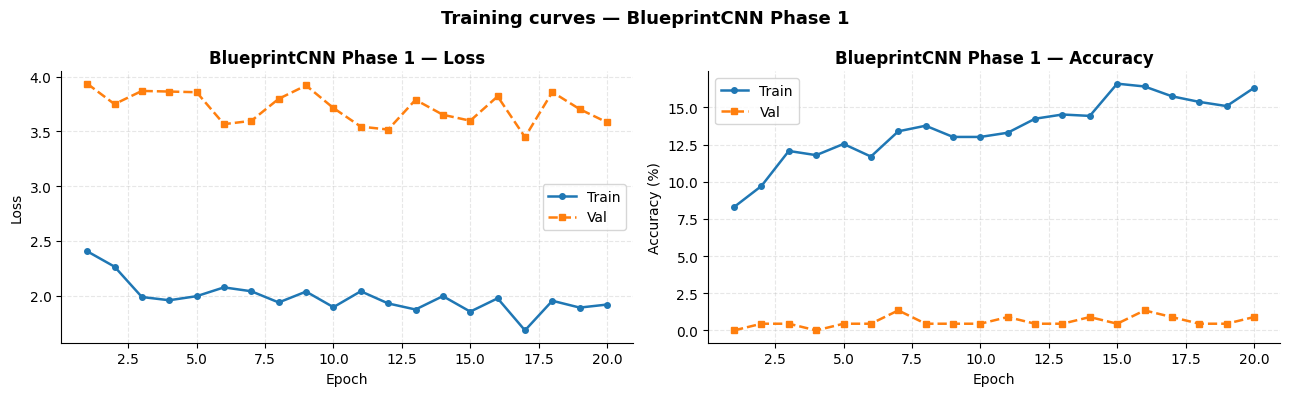

Saved: curves_BlueprintCNN.png


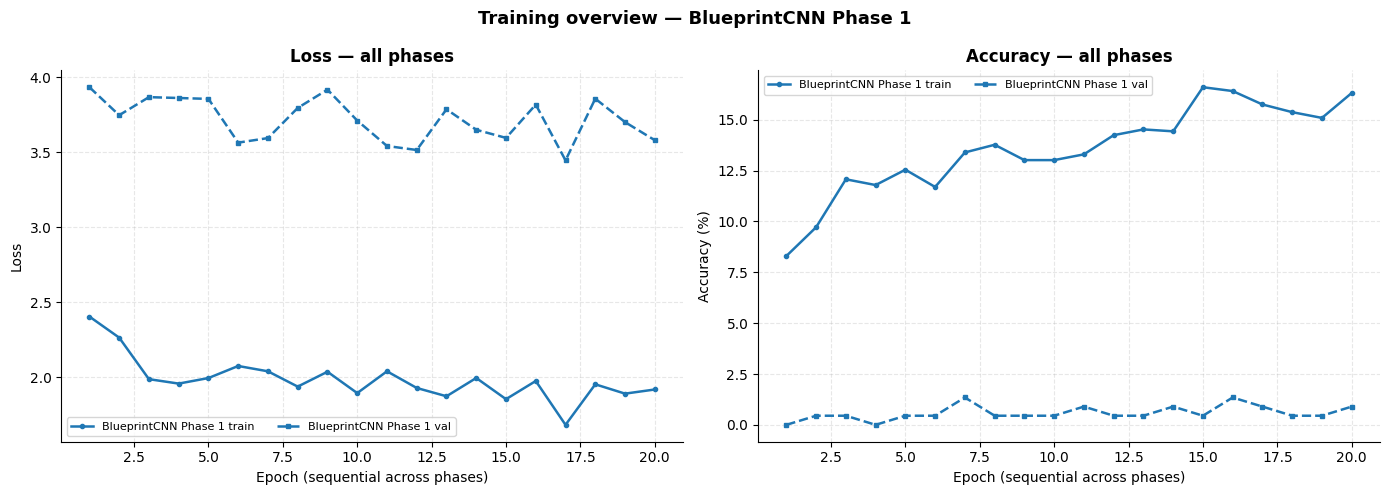

Saved: curves_BlueprintCNN_combined.png

BlueprintCNN  —  Test Results
  Accuracy       : 1.28%
  Weighted F1    : 0.0082
  Correct / Total: 3 / 234

                               precision    recall  f1-score   support

              bathroom_toilet       0.00      0.00      0.00        62
                bedroom_relax       0.02      1.00      0.04         1
                changing_room       0.00      0.00      0.00        17
                   class_room       0.00      0.00      0.00        12
      common_room_living_room       0.50      0.04      0.08        23
        dining_room_cafeteria       0.00      0.00      0.00         7
             hallway_corridor       0.00      0.00      0.00        21
                      kitchen       0.00      0.00      0.00         7
                 laundry_room       0.00      0.00      0.00         5
                      library       0.00      0.00      0.00         1
               lobby_entrance       0.00      0.00      0.00        

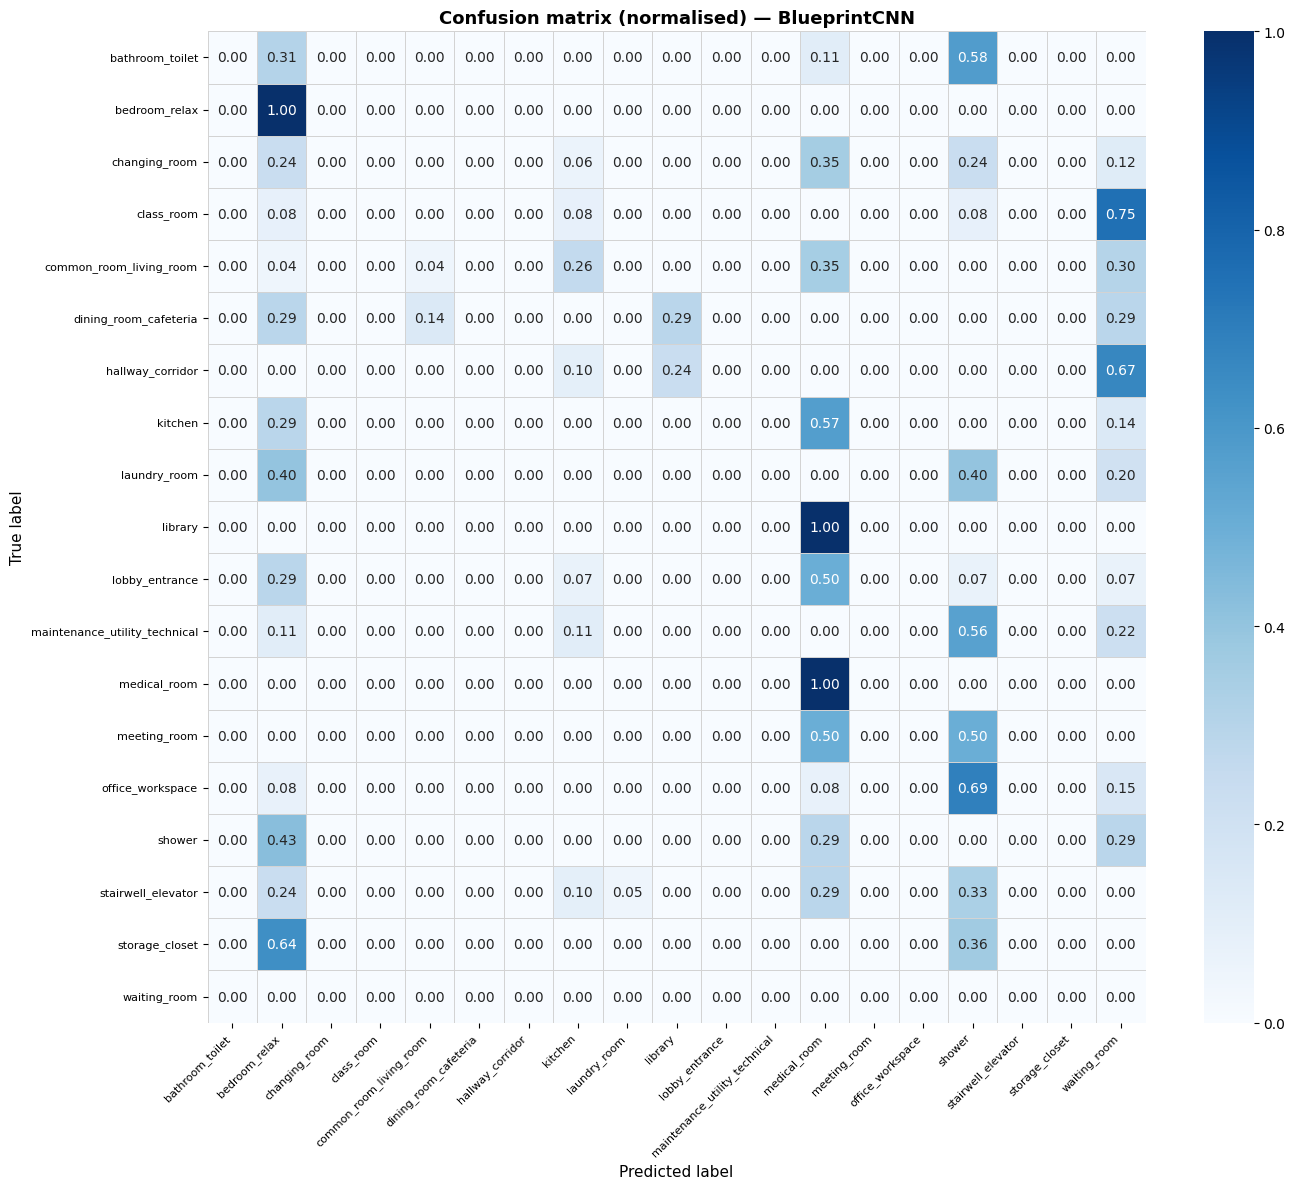

Saved: confusion_BlueprintCNN.png
BlueprintCNN checkpoint saved.


In [19]:
plot_training_curves([h_cnn], ['BlueprintCNN Phase 1'], 'curves_BlueprintCNN.png')

cnn_preds, cnn_targets, cnn_acc, cnn_f1 = evaluate_model(
    cnn_model, test_loader_bp, 'BlueprintCNN'
)
plot_confusion_matrix(cnn_targets, cnn_preds, 'BlueprintCNN', 'confusion_BlueprintCNN.png')

torch.save(cnn_model.state_dict(), 'BlueprintCNN_best.pth')
print('BlueprintCNN checkpoint saved.')

## 9  —  Train EfficientNetB0 (Two-Phase Transfer Learning)

In [20]:
gc.collect()
torch.cuda.empty_cache()

# Build loaders with ImageNet normalisation for EfficientNetB0
train_loader_eff, val_loader_eff, test_loader_eff = make_loaders(
    train_transforms_eff, val_transforms_eff
)

eff_model = build_efficientnet(NUM_CLASSES).to(DEVICE)
print('EfficientNetB0')
print(f'  Trainable params (Phase 1) : {count_params(eff_model):,}')
print(f'  Total params               : {count_params(eff_model, trainable_only=False):,}')

# ── Phase 1 — frozen backbone, train head only ────────────────────────────────
h_eff1 = train_phase(
    model=eff_model,
    model_name='EfficientNetB0',
    train_loader=train_loader_eff,
    val_loader=val_loader_eff,
    phase=1,
    lr=1e-3,
    n_epochs=EPOCHS,
    label_smoothing=0.0,
    weight_decay=1e-4,
)


EfficientNetB0
  Trainable params (Phase 1) : 333,331
  Total params               : 4,340,879

====================================================================  EfficientNetB0
  lr=0.001  label_smoothing=0.0  weight_decay=0.0001  epochs=20
  Phase 1  |  trainable params: 333,331

  Epoch       train_acc   train_loss    val_acc   val_loss
  ----------------------------------------------------------
  Epoch 1   /20  train_acc: 0.1509  train_loss: 2.0526  val_acc: 0.0045  val_loss: 3.4027  ✓
  Epoch 2   /20  train_acc: 0.2660  train_loss: 1.4769  val_acc: 0.0493  val_loss: 2.8607  ✓
  Epoch 3   /20  train_acc: 0.2708  train_loss: 1.5245  val_acc: 0.0673  val_loss: 3.0603
  Epoch 4   /20  train_acc: 0.2840  train_loss: 1.3918  val_acc: 0.0717  val_loss: 2.7592  ✓
  Epoch 5   /20  train_acc: 0.3075  train_loss: 1.3235  val_acc: 0.0852  val_loss: 2.5938  ✓
  Epoch 6   /20  train_acc: 0.3283  train_loss: 1.1434  val_acc: 0.1614  val_loss: 2.6569
  Epoch 7   /20  train_acc: 0.3396  train_

In [21]:
# ── Phase 2 — unfreeze last 30 backbone layers, fine-tune at low LR ───────────
trainable = unfreeze_backbone(eff_model, last_n_layers=30)
print(f'Backbone partially unfrozen — trainable params: {trainable:,}')

h_eff2 = train_phase(
    model=eff_model,
    model_name='EfficientNetB0',
    train_loader=train_loader_eff,
    val_loader=val_loader_eff,
    phase=2,
    lr=2e-5,
    n_epochs=EPOCHS,
    label_smoothing=0.0,
    weight_decay=1e-4,
)


Backbone partially unfrozen — trainable params: 4,340,879

====================================================================  EfficientNetB0
  lr=2e-05  label_smoothing=0.0  weight_decay=0.0001  epochs=20
  Phase 2  |  trainable params: 4,340,879

  Epoch       train_acc   train_loss    val_acc   val_loss
  ----------------------------------------------------------
  Epoch 1   /20  train_acc: 0.4208  train_loss: 1.0675  val_acc: 0.3453  val_loss: 2.0245  ✓
  Epoch 2   /20  train_acc: 0.4830  train_loss: 0.8485  val_acc: 0.3812  val_loss: 2.0015  ✓
  Epoch 3   /20  train_acc: 0.4783  train_loss: 0.7994  val_acc: 0.3543  val_loss: 2.0243
  Epoch 4   /20  train_acc: 0.4943  train_loss: 0.8282  val_acc: 0.3363  val_loss: 1.9827  ✓
  Epoch 5   /20  train_acc: 0.4896  train_loss: 0.8616  val_acc: 0.4036  val_loss: 1.9059  ✓
  Epoch 6   /20  train_acc: 0.5198  train_loss: 0.6985  val_acc: 0.4126  val_loss: 1.8246  ✓
  Epoch 7   /20  train_acc: 0.5321  train_loss: 0.7263  val_acc: 0.3946  v

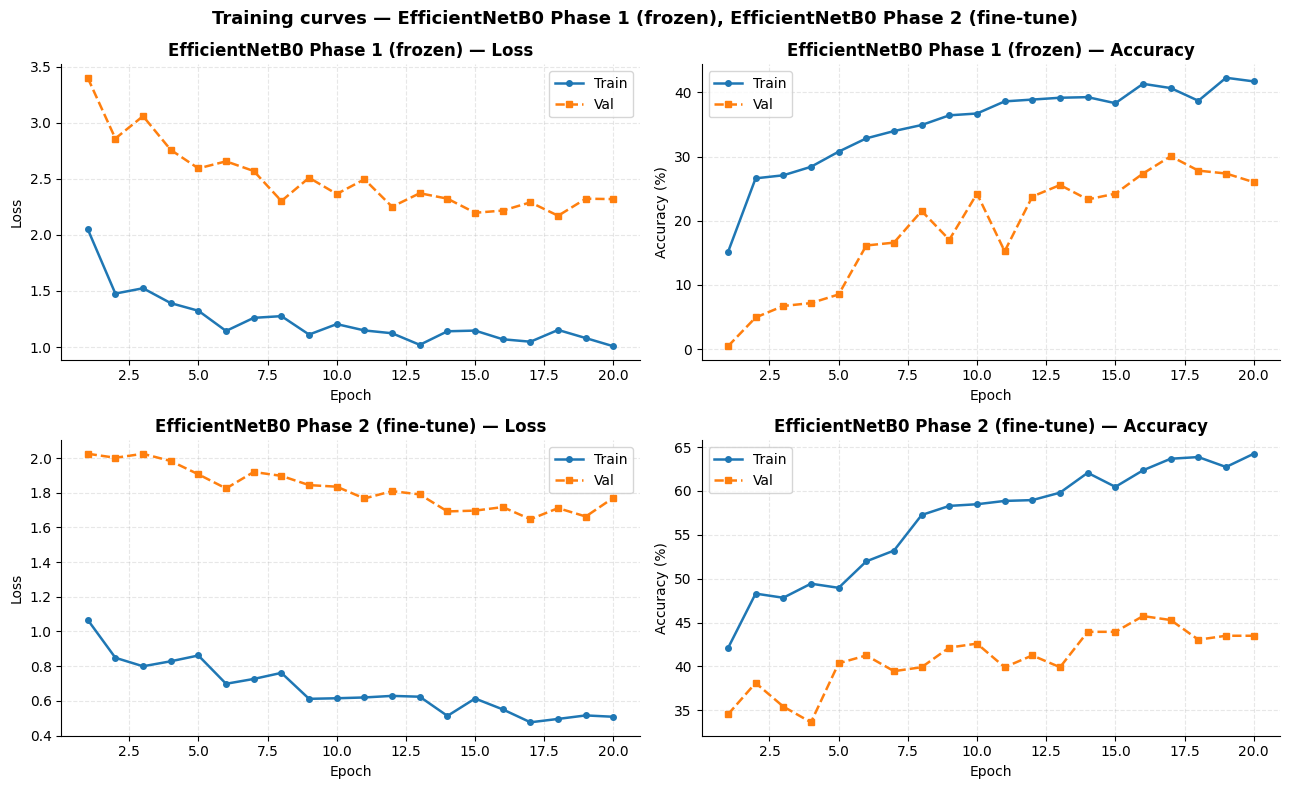

Saved: curves_EfficientNetB0.png


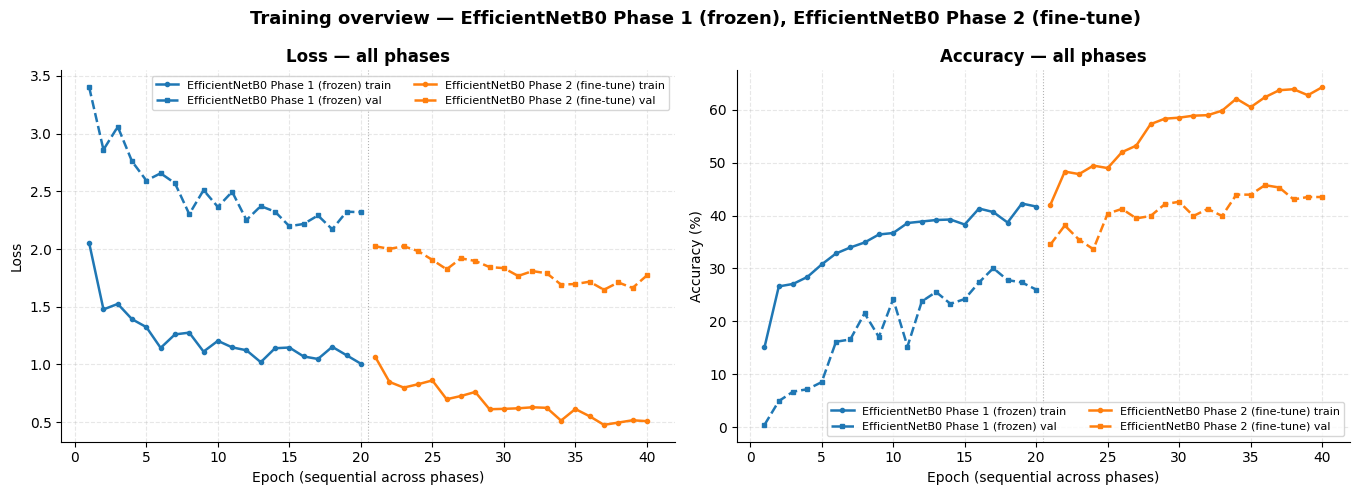

Saved: curves_EfficientNetB0_combined.png

EfficientNetB0  —  Test Results
  Accuracy       : 41.03%
  Weighted F1    : 0.4095
  Correct / Total: 96 / 234

                               precision    recall  f1-score   support

              bathroom_toilet       0.88      0.74      0.81        62
                bedroom_relax       0.00      0.00      0.00         1
                changing_room       0.45      0.82      0.58        17
                   class_room       0.00      0.00      0.00        12
      common_room_living_room       0.50      0.13      0.21        23
        dining_room_cafeteria       0.00      0.00      0.00         7
             hallway_corridor       0.50      0.05      0.09        21
                      kitchen       0.17      0.29      0.21         7
                 laundry_room       0.12      0.60      0.21         5
                      library       0.00      0.00      0.00         1
               lobby_entrance       0.00      0.00      0.00  

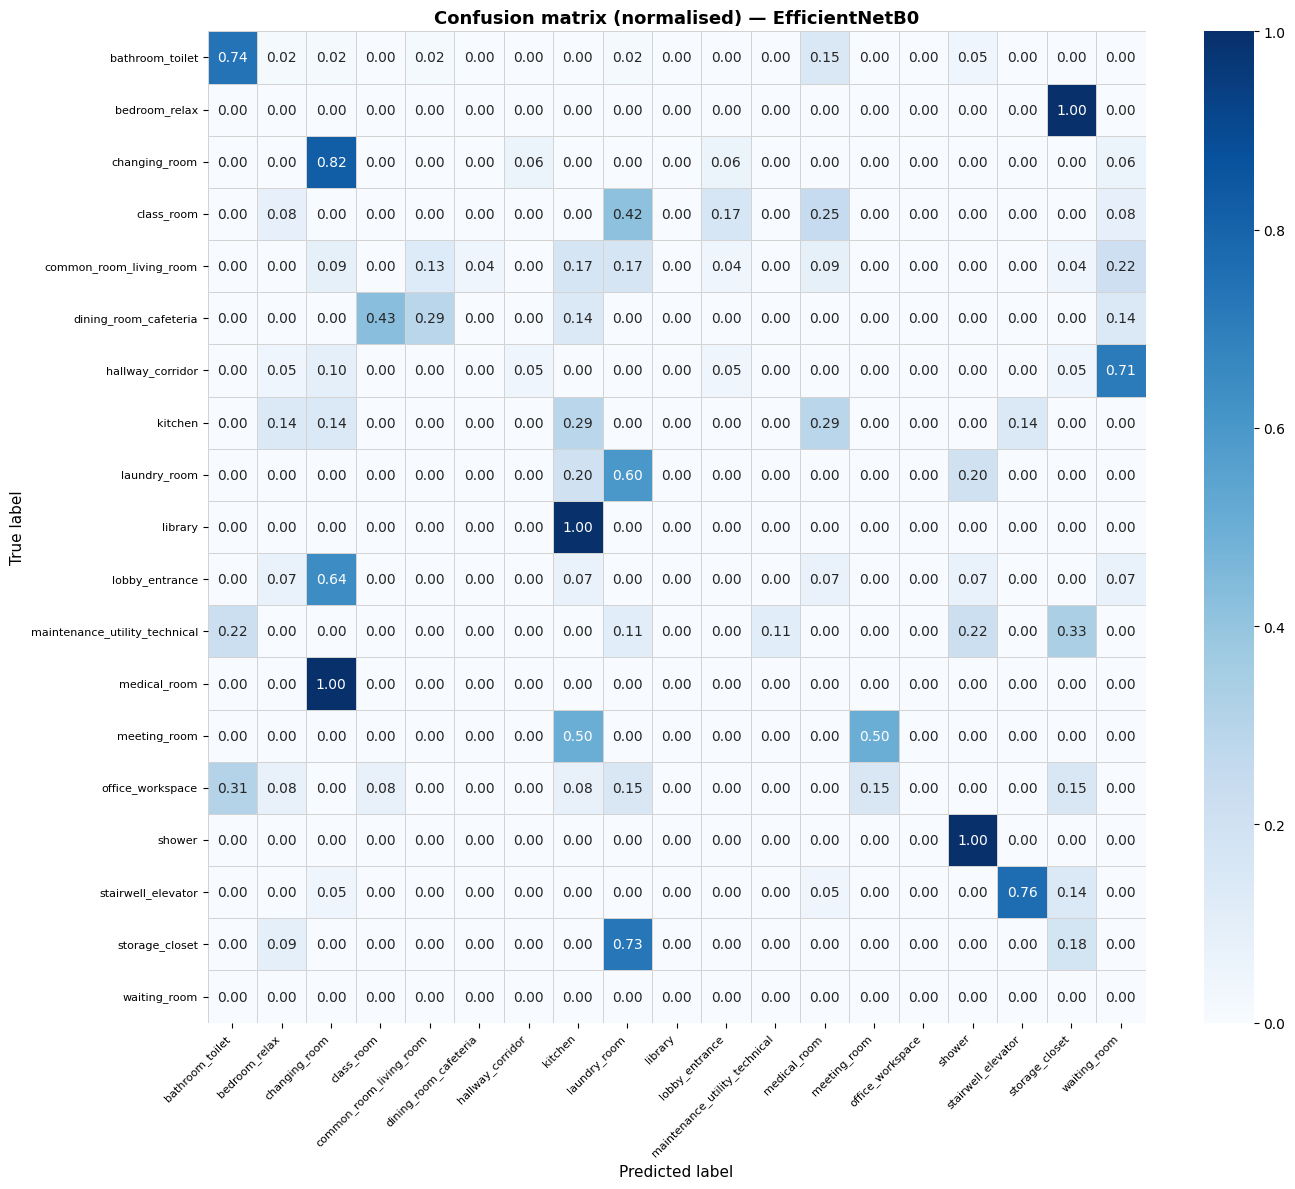

Saved: confusion_EfficientNetB0.png
EfficientNetB0 checkpoint saved.


In [22]:
plot_training_curves(
    [h_eff1, h_eff2],
    ['EfficientNetB0 Phase 1 (frozen)', 'EfficientNetB0 Phase 2 (fine-tune)'],
    'curves_EfficientNetB0.png',
)

eff_preds, eff_targets, eff_acc, eff_f1 = evaluate_model(
    eff_model, test_loader_eff, 'EfficientNetB0'
)
plot_confusion_matrix(eff_targets, eff_preds, 'EfficientNetB0', 'confusion_EfficientNetB0.png')

torch.save(eff_model.state_dict(), 'EfficientNetB0_best.pth')
print('EfficientNetB0 checkpoint saved.')

## 10  —  Model Comparison

         Model  Accuracy  Weighted F1
  BlueprintCNN  0.012821     0.008211
EfficientNetB0  0.410256     0.409525


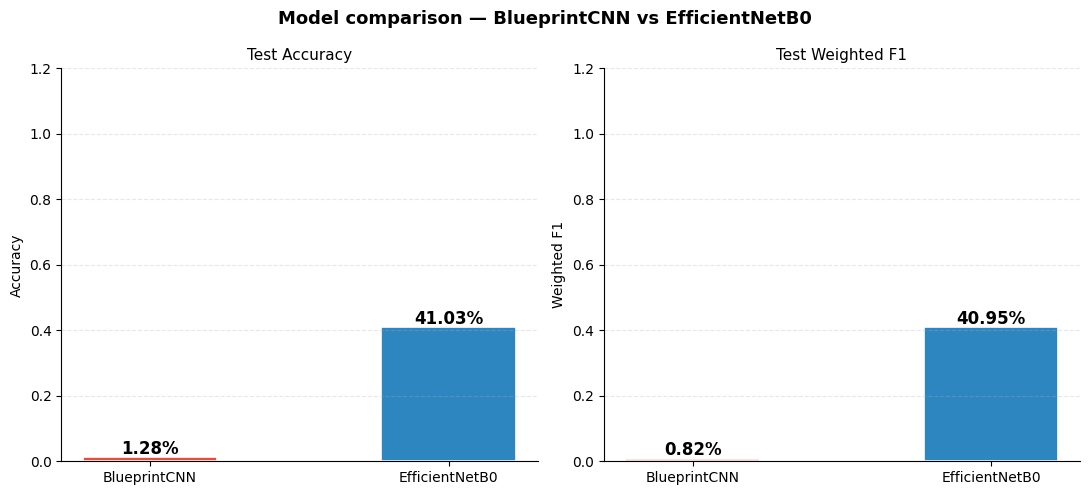

Saved: comparison.png


In [23]:
MODEL_COLORS = {'BlueprintCNN': '#E74C3C', 'EfficientNetB0': '#2E86C1'}

results = pd.DataFrame([
    {'Model': 'BlueprintCNN',   'Accuracy': cnn_acc, 'Weighted F1': cnn_f1},
    {'Model': 'EfficientNetB0', 'Accuracy': eff_acc, 'Weighted F1': eff_f1},
])

print(results.to_string(index=False))

# ── Accuracy & F1 bar chart ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Model comparison — BlueprintCNN vs EfficientNetB0',
             fontsize=13, fontweight='bold')

for ax, metric in zip(axes, ['Accuracy', 'Weighted F1']):
    values = results[metric].values
    names  = results['Model'].values
    bars   = ax.bar(
        names, values,
        color=[MODEL_COLORS[n] for n in names],
        width=0.45, edgecolor='white', linewidth=1.2,
    )
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f'{val*100:.2f}%', ha='center', fontsize=12, fontweight='bold',
        )
    ax.set_ylim(0, 1.2)
    ax.set_title(f'Test {metric}', fontsize=11)
    ax.set_ylabel(metric)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: comparison.png')

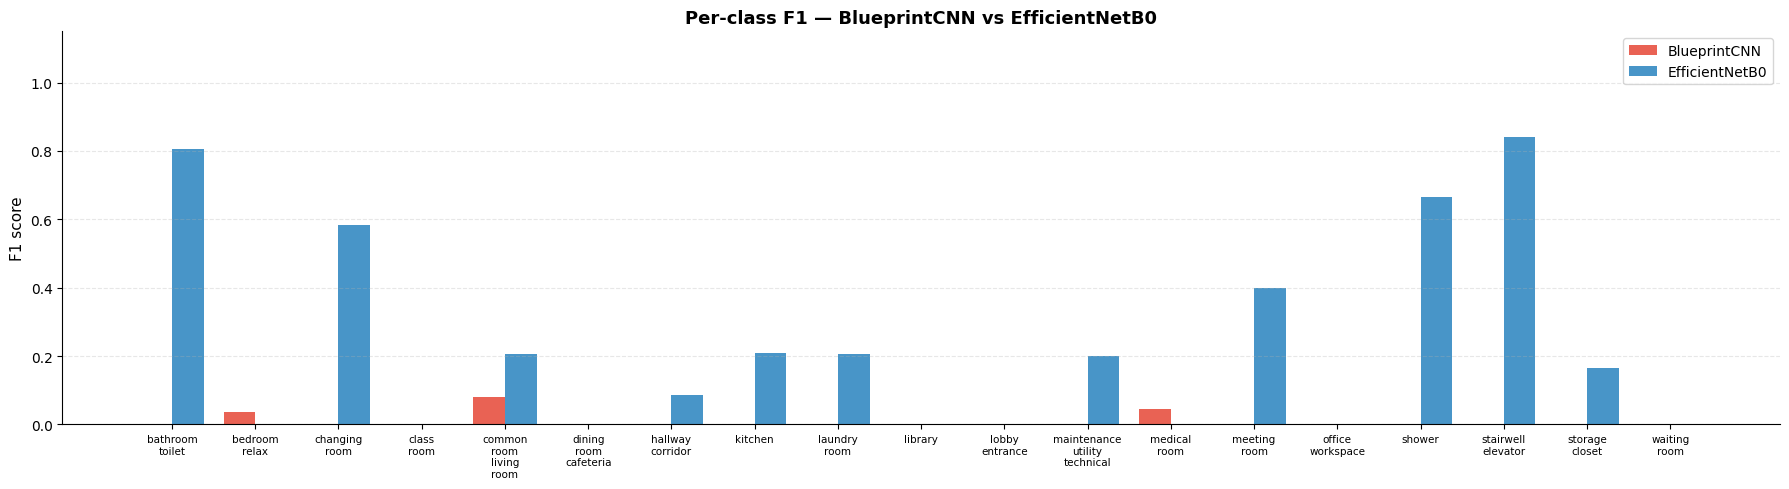

Saved: f1_per_class.png


In [24]:
# ── Per-class F1 grouped bar chart ────────────────────────────────────────────
x     = np.arange(NUM_CLASSES)
width = 0.38

fig, ax = plt.subplots(figsize=(18, 5))

for offset, (name, preds, targets) in zip(
    [-width / 2, width / 2],
    [
        ('BlueprintCNN',   cnn_preds, cnn_targets),
        ('EfficientNetB0', eff_preds, eff_targets),
    ],
):
    f1_per_class = f1_score(
        targets, preds,
        average=None,
        labels=list(range(NUM_CLASSES)),
        zero_division=0,
    )
    ax.bar(
        x + offset, f1_per_class, width,
        label=name, color=MODEL_COLORS[name], alpha=0.88,
    )

ax.set_xticks(x)
ax.set_xticklabels([c.replace('_', '\n') for c in ALL_CLASSES], fontsize=7.5)
ax.set_ylim(0, 1.15)
ax.set_ylabel('F1 score', fontsize=11)
ax.set_title('Per-class F1 — BlueprintCNN vs EfficientNetB0',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('f1_per_class.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: f1_per_class.png')

In [25]:
# ── Summary table ─────────────────────────────────────────────────────────────
print('\n' + '=' * 52)
print(f'  {"Model":<20}  {"Accuracy":>10}  {"Weighted F1":>11}')
print('  ' + '-' * 48)
for _, row in results.iterrows():
    print(f'  {row["Model"]:<20}  {row["Accuracy"]*100:>9.2f}%  {row["Weighted F1"]:>11.4f}')
print('=' * 52)
best_model = results.loc[results['Accuracy'].idxmax(), 'Model']
print(f'\n  Best model : {best_model}')


  Model                   Accuracy  Weighted F1
  ------------------------------------------------
  BlueprintCNN               1.28%       0.0082
  EfficientNetB0            41.03%       0.4095

  Best model : EfficientNetB0


## 11  —  EfficientNetB0 — Sample Predictions

Correctly classified : 96 / 234 images


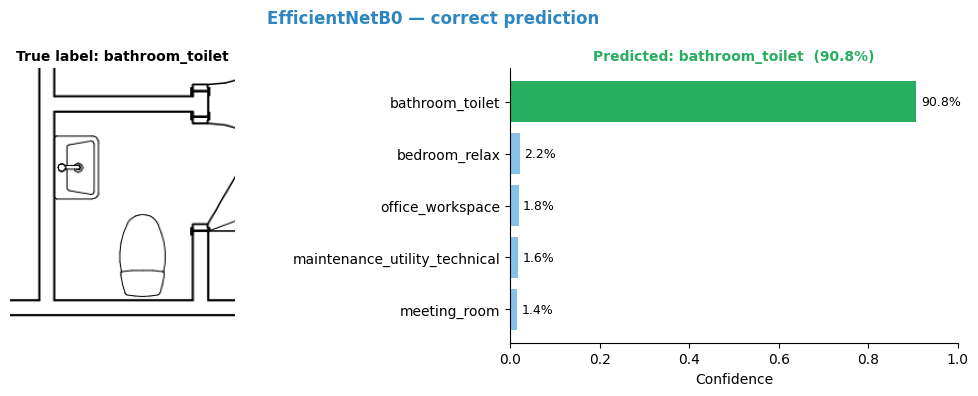

Saved: prediction_bathroom_toilet_EfficientNetB0.png


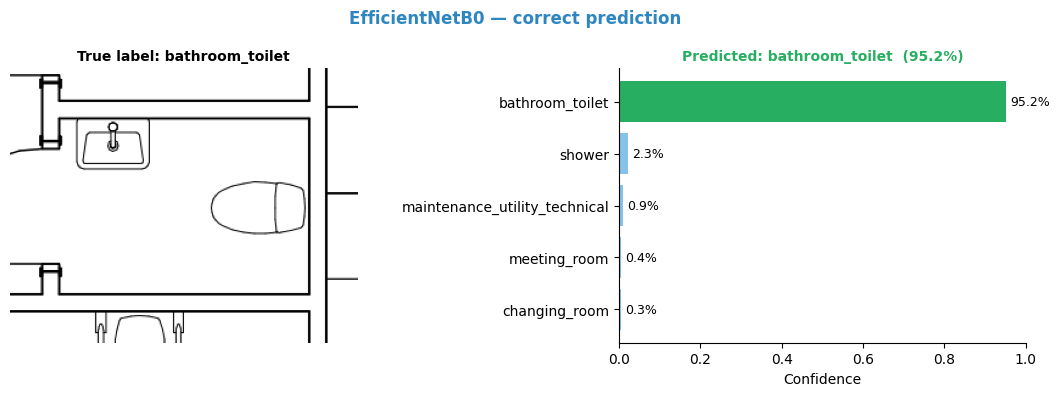

Saved: prediction_bathroom_toilet_EfficientNetB0.png


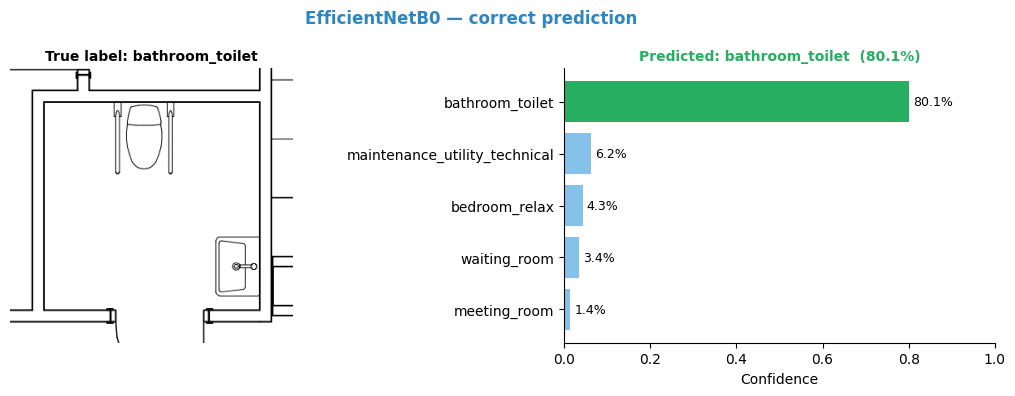

Saved: prediction_bathroom_toilet_EfficientNetB0.png


In [26]:
correct_indices = [
    i for i, (p, t) in enumerate(zip(eff_preds, eff_targets)) if p == t
]
print(f'Correctly classified : {len(correct_indices)} / {len(eff_preds)} images')

# Show up to 3 correct predictions
for idx in correct_indices[:3]:
    true_label  = IDX_TO_CLASS[eff_targets[idx]]
    img         = Image.open(test_paths[idx]).convert('RGB')
    arr         = preprocess(img)
    tensor      = val_transforms_eff(image=arr)['image'].unsqueeze(0).to(DEVICE)

    eff_model.eval()
    with torch.no_grad():
        probs = F.softmax(eff_model(tensor), dim=1).squeeze().cpu().numpy()

    top_idx    = probs.argsort()[::-1][:5]
    top_labels = [IDX_TO_CLASS[i] for i in top_idx]
    top_probs  = probs[top_idx]

    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(11, 4))
    fig.suptitle('EfficientNetB0 — correct prediction',
                 fontsize=12, fontweight='bold', color=MODEL_COLORS['EfficientNetB0'])

    ax_img.imshow(img)
    ax_img.set_title(f'True label: {true_label}', fontsize=10, fontweight='bold')
    ax_img.axis('off')

    bar_colors = ['#27AE60' if i == 0 else '#85C1E9' for i in range(len(top_labels))]
    ax_bar.barh(top_labels[::-1], top_probs[::-1], color=bar_colors[::-1])
    ax_bar.set_xlim(0, 1)
    ax_bar.set_xlabel('Confidence', fontsize=10)
    ax_bar.set_title(
        f'Predicted: {top_labels[0]}  ({top_probs[0]*100:.1f}%)',
        fontsize=10, color='#27AE60', fontweight='bold',
    )
    for i, val in enumerate(top_probs[::-1]):
        ax_bar.text(val + 0.01, i, f'{val*100:.1f}%', va='center', fontsize=9)
    ax_bar.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    save_name = f'prediction_{true_label}_EfficientNetB0.png'
    plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_name}')

## 12  —  Download All Outputs

In [27]:
from google.colab import files

OUTPUT_FILES = [
    'class_distribution.png',
    'sample_per_class.png',
    'curves_BlueprintCNN.png',
    'curves_BlueprintCNN_combined.png',
    'curves_EfficientNetB0.png',
    'curves_EfficientNetB0_combined.png',
    'confusion_BlueprintCNN.png',
    'confusion_EfficientNetB0.png',
    'comparison.png',
    'f1_per_class.png',
    'BlueprintCNN_best.pth',
    'EfficientNetB0_best.pth',
]

print('Downloading outputs...')
for fname in OUTPUT_FILES:
    if os.path.exists(fname):
        files.download(fname)
        print(f'  Downloaded : {fname}')
    else:
        print(f'  Missing    : {fname}')
print('Done.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloaded : class_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloaded : sample_per_class.png


... (26 outputs left out)

  Downloaded : BlueprintCNN_best.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloaded : EfficientNetB0_best.pth
Done.
